In [1]:
import numpy as np

class MyLinearRegression:
  def __init__(self, learning_rate=0.01,iterations=1000):
    self.lr = learning_rate
    self.iterations = iterations
    self.weights = None
    self.bias = None
    
  def fit(self, X,y):
    n_samples,n_features = X.shape
    
    # 1. Initialize parameters (weights and bias) to zeros
    self.weights = np.zeros(n_features)
    self.bias = 0
    
    #Gradient Descent
    
    for _ in range(self.iterations):
      y_predicted = np.dot(X,self.weights) + self.bias
    
      # Step B: Calculate Gradients (dw and db)
      # Formula: (2/n) * sum((y_pred - y) * x)
      
      dw = (1/n_samples) * np.dot(X.T, (y_predicted - y))
      db = (1/n_features) * np.sum(y_predicted - y) 
      
      # Step C: Update Parameters
      # w = w - learning_rate * dw
              
      self.weights = self.weights - self.lr * dw
      self.bias = self.bias - self.lr * db
            
            
  def predict(self,X):
    return np.dot(X, self.weights) + self.bias
    

In [2]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [3]:
from sklearn.model_selection import train_test_split
import pandas as pd

df1 = pd.read_csv('data/Salary_dataset.csv')
df1.head() 



,Unnamed: 0,YearsExperience,Salary
0,0,1.2,39344.0
1,1,1.4,46206.0
2,2,1.6,37732.0
3,3,2.1,43526.0
4,4,2.3,39892.0


In [4]:
X_train,X_test, y_train, y_test = train_test_split(df1['YearsExperience'].values, df1['Salary'].values, test_size=0.2, random_state=42)
X_train = X_train.reshape(-1,1)
X_test = X_test.reshape(-1,1)

regressor = MyLinearRegression(learning_rate=0.01, iterations=1000)

regressor.fit(X_train, y_train)

predictions = regressor.predict(X_test)

In [5]:
predictions

array([115791.21011287,  71499.27809463, 102597.86866063,  75268.80422384,
        55478.79204548,  60190.69970699])

In [6]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train, y_train)
model_predictions = model.predict(X_test)
model_predictions

array([115791.21011287,  71499.27809463, 102597.86866063,  75268.80422384,
        55478.79204548,  60190.69970699])

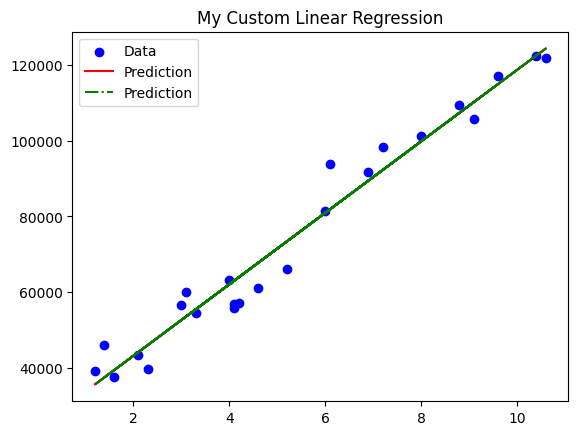

Learned Weight (Slope): [9423.81532303]
Learned Bias (Intercept): 24380.201479473784


In [7]:
import matplotlib.pyplot as plt

plt.scatter(X_train, y_train, color='blue', label='Data')
plt.plot(X_train, regressor.predict(X_train), color='red', label='Prediction')
plt.plot(X_train, model.predict(X_train),ls="-.", color='green', label='Prediction')
plt.title('My Custom Linear Regression')
plt.legend()
plt.show()

print(f"Learned Weight (Slope): {regressor.weights}")
print(f"Learned Bias (Intercept): {regressor.bias}")

In [26]:
class RawLinearRegression:
  def __init__(self, learning_rate=0.01, iterations=1000):
    self.lr = learning_rate          # how big of a step to take
    self.iterations = iterations     # how many steps to take
    self.weights = 0              # start with slope as 0
    self.bias = 0                 # start with intercept as 0
    self.history = []                # to track error over time
    self.cost_history = []
    
  def fit(self, X,y):
    """
    X: list of inputs
    y: list of outputs 
    """
    
    n_samples = len(X)
    
    for i in range(self.iterations):
      
      # --- STEP 1: MAKE PREDICTIONS ---
      # Formula: y = w*x + b
      predictions = []
      for j in range(n_samples):
        # print(X[j])
        pred = (self.weights * X[j]) + self.bias
        predictions.append(pred)
        
      current_loss = 0
      for j in range(n_samples):
        current_loss += (predictions[j] - y[j]) ** 2
      self.cost_history.append((1/(2*n_samples)) * current_loss)
        
      # --- STEP 2: CALCULATE GRADIENTS ---  
      dw = 0.0 #derivative for weights
      db = 0.0 # derivative for bias
      
      for j in range(n_samples):
        error = (predictions[j] - y[j])
        
        dw +=error * X[j]
        db += error
        
        dw = (2/n_samples) * dw
        db = (2/n_samples) * db
        
        # --- STEP 3: UPDATE PARAMETERS ---
        # Math: w_new = w_old - (lr * gradient)
        
        self.weights = self.weights - (self.lr * dw)
        self.bias = self.bias - (self.lr * db)
        
  def predict(self, X):
    results = []
    
    for val in X:
      pred = (self.weights * val ) + self.bias
      results.append(pred)
    return results

In [27]:
raw_regressor = RawLinearRegression(learning_rate=0.01, iterations=1000)
# print(X_train, y_train)
raw_regressor.fit(X_train, y_train)
raw = raw_regressor.predict(X_test)
ans = model.predict(X_test)
for i in range(len(raw)):
  print(f"MyRawLR Prediction: {raw[i]}, Sklearn LR Prediction: {ans[i]}")
  
print("My Weights:", raw_regressor.weights)
print("Sklearn Coef:", model.coef_)

print("My Bias:", raw_regressor.bias)
print("Sklearn Intercept:", model.intercept_)



MyRawLR Prediction: [115861.95941155], Sklearn LR Prediction: 115791.21011287419
MyRawLR Prediction: [71425.81469947], Sklearn LR Prediction: 71499.2780946286
MyRawLR Prediction: [102625.66098668], Sklearn LR Prediction: 102597.86866063082
MyRawLR Prediction: [75207.61424943], Sklearn LR Prediction: 75268.80422384098
MyRawLR Prediction: [55353.16661212], Sklearn LR Prediction: 55478.79204547593
MyRawLR Prediction: [60080.41604957], Sklearn LR Prediction: 60190.699706991414
My Weights: [9454.49887491]
Sklearn Coef: [9423.81532303]
My Bias: [24153.32032491]
Sklearn Intercept: 24380.20147947369


C:\Users\Pooja\AppData\Local\Temp\ipykernel_14744\723468024.py:3: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  plt.title(f"Loss Curve (Final Cost: {int(raw_regressor.cost_history[-1])})")


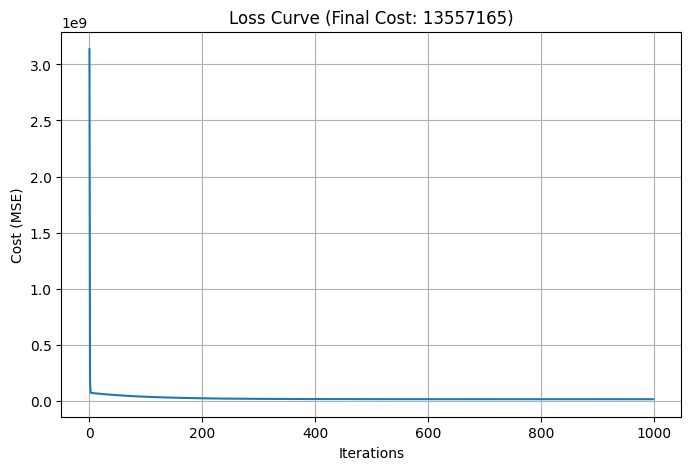

Final Weights: [9454.49887491]
Final Bias: [24153.32032491]


In [29]:
plt.figure(figsize=(8, 5))
plt.plot(raw_regressor.cost_history)
plt.title(f"Loss Curve (Final Cost: {int(raw_regressor.cost_history[-1])})")
plt.xlabel("Iterations")
plt.ylabel("Cost (MSE)")
plt.grid(True)
plt.show()

print("Final Weights:", raw_regressor.weights)
print("Final Bias:", raw_regressor.bias)